# Project 3: Unsupervised clustering of multi-band vegetation optical depth

**Objective.** Test whether an unsupervised pipeline can group pixels by their multi-band vegetation signature, and whether the groups match land cover. Use a leakage-safe spatial train/test design and compare the result with a single-band baseline.

**Problem.** Vegetation optical depth (VOD) from passive microwave sensors depends on canopy structure and water content. Across several frequency bands, the pattern of values between bands carries information about vegetation type. Land-cover labels are often unavailable or out of date, so an unsupervised grouping can be a useful first look.

**Data.** This notebook uses a **synthetic** scene from `src/vod_clustering/synthetic.py`, with a fixed seed. Three band names are generic placeholders for three frequencies. The class means and noise are invented, and the scene is designed so that both the amplitude and the shape across bands carry signal. No real satellite product is used or distributed here. A real analysis would start from a public VOD product and a land-cover map, and their licences and access terms would be checked first.

**Method discipline.**
- Land-cover labels are used only for evaluation, never for fitting.
- The scaler and PCA are fitted on training pixels only. Test pixels are assigned with `predict`.
- Train and test regions are separated by a column buffer, so that neighbouring pixels cannot leak across the split.
- The number of clusters is chosen from a silhouette sweep on training data.

## 1. Imports and configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

sys.path.insert(0, str(Path("../src").resolve()))
from vod_clustering import (
    baseline_quantile_labels, build_pipeline, choose_k, evaluate_assignments,
    harmonise, make_scene, seed_stability, spatial_split,
)
from vod_clustering.synthetic import BAND_NAMES, CLASS_NAMES

SEED = 0
SHAPE = (120, 120)
TRAIN_FRAC = 0.5
BUFFER_COLS = 3
K_RANGE = range(2, 7)
BASELINE_BAND = BAND_NAMES.index("mid_freq")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

## 2. Generate the scene and check it
The scene is synthetic. Before any modelling, check the missing-data fraction, the share of pixels that pass the physical range check, and the class balance.

In [2]:
scene = make_scene(SHAPE, seed=SEED)
features, valid = harmonise(scene.bands)

qa = pd.DataFrame({
    "band": BAND_NAMES,
    "missing (%)": [round(100 * np.isnan(scene.bands[b]).mean(), 2) for b in range(len(BAND_NAMES))],
    "median VOD": [round(float(np.nanmedian(scene.bands[b])), 3) for b in range(len(BAND_NAMES))],
}).set_index("band")
print(f"Pixels: {scene.land_cover.size}, valid for all bands: {valid.sum()} ({100 * valid.mean():.1f}%)")
print(qa)
print()
print("Class balance (share of pixels):")
pd.Series(
    np.bincount(scene.land_cover.ravel(), minlength=len(CLASS_NAMES)) / scene.land_cover.size,
    index=CLASS_NAMES,
).round(3)

Pixels: 14400, valid for all bands: 13132 (91.2%)
           missing (%)  median VOD
band                              
low_freq          2.98       0.448
mid_freq          3.07       0.500
high_freq         3.07       0.546

Class balance (share of pixels):


forest       0.35
shrubland    0.30
cropland     0.20
grassland    0.15
dtype: float64

**Quality checks.** The gaps are close to the configured 3% per band, and the valid-pixel share follows from requiring all three bands to be present. Every class is represented. These are checks on the generator, so they confirm the scene is what the code intends and nothing more.

## 3. Exploratory view of the bands
The scatter plot below uses land cover for colour only. It shows what the clustering can use, and is not an input to the model.

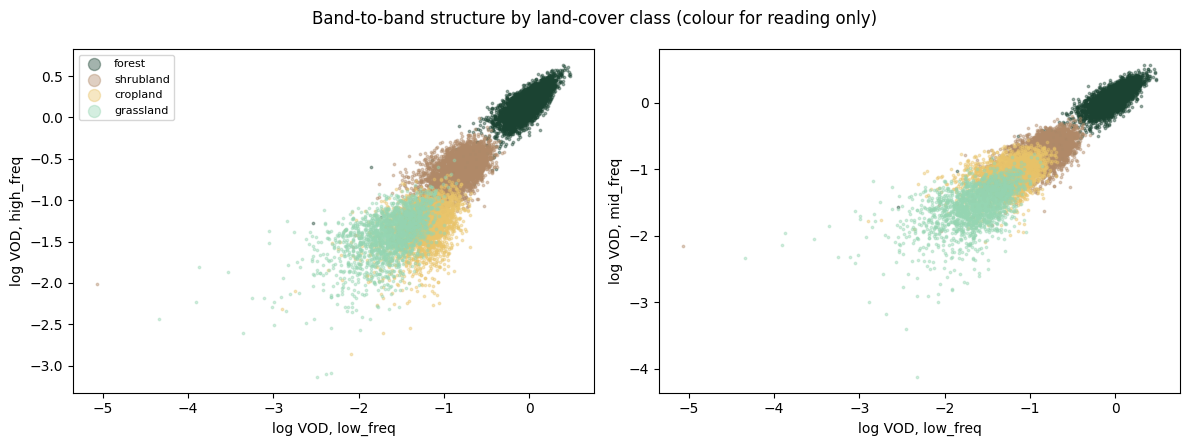

In [3]:
log_bands = np.log(np.where(scene.bands > 0, scene.bands, np.nan))  # log needs positive values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pairs = [(0, 2), (0, 1)]
colors = ["#1b4332", "#b08968", "#e9c46a", "#95d5b2"]
for ax, (i, j) in zip(axes, pairs):
    for c, name in enumerate(CLASS_NAMES):
        m = (scene.land_cover == c) & valid
        ax.scatter(log_bands[i][m], log_bands[j][m], s=3, alpha=0.4, color=colors[c], label=name)
    ax.set_xlabel(f"log VOD, {BAND_NAMES[i]}")
    ax.set_ylabel(f"log VOD, {BAND_NAMES[j]}")
axes[0].legend(markerscale=5, fontsize=8)
fig.suptitle("Band-to-band structure by land-cover class (colour for reading only)")
fig.tight_layout()
fig.savefig(FIG_DIR / "band_scatter.png", dpi=120)
plt.show()

## 4. Spatial split with a buffer
Left-right split by column. The buffer columns belong to neither set. The table reports how many pixels fall in each set.

In [4]:
train_mask, test_mask = spatial_split(SHAPE, train_frac=TRAIN_FRAC, buffer_cols=BUFFER_COLS)
train_sel = train_mask[valid]
test_sel = test_mask[valid]
X_train, X_test = features[train_sel], features[test_sel]
y_train = scene.land_cover[valid][train_sel]  # not used for fitting
y_test = scene.land_cover[valid][test_sel]    # evaluation only

pd.DataFrame({
    "set": ["train", "buffer (excluded)", "test"],
    "valid pixels": [int(valid[train_mask].sum()), int((valid & ~train_mask & ~test_mask).sum()), int(valid[test_mask].sum())],
})

,set,valid pixels
0,train,6237
1,buffer (excluded),651
2,test,6244


## 5. Choose the number of clusters from training data only
Silhouette scores are computed on the PCA space of a training sample. No land-cover labels are used here.

{2: 0.608, 3: 0.618, 4: 0.581, 5: 0.528, 6: 0.448}
Highest silhouette k: 3


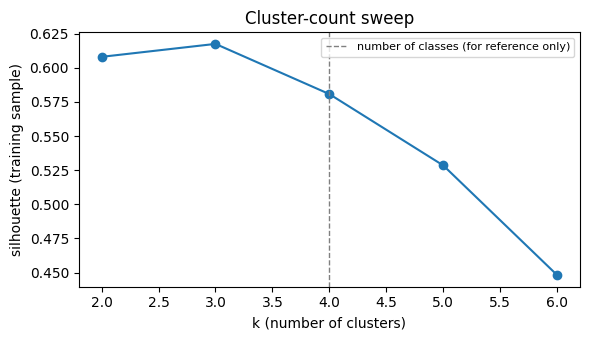

In [5]:
sil = choose_k(X_train, K_RANGE, seed=SEED, sample_size=3000)
k_best = max(sil, key=sil.get)
print({k: round(v, 3) for k, v in sil.items()})
print("Highest silhouette k:", k_best)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(sil.keys()), list(sil.values()), marker="o")
ax.axvline(len(CLASS_NAMES), color="grey", ls="--", lw=1, label="number of classes (for reference only)")
ax.set_xlabel("k (number of clusters)")
ax.set_ylabel("silhouette (training sample)")
ax.set_title("Cluster-count sweep")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "k_selection.png", dpi=120)
plt.show()

## 6. Fit on training data and evaluate on the held-out region

In [6]:
K = k_best
pipe = build_pipeline(K, n_components=2, seed=SEED).fit(X_train)
Z_test = pipe[:-1].transform(X_test)
labels_test = pipe.predict(X_test)

metrics = evaluate_assignments(labels_test, y_test, Z_test)
baseline_labels = baseline_quantile_labels(X_train, X_test, band=BASELINE_BAND, k=K)
baseline_metrics = evaluate_assignments(baseline_labels, y_test, Z_test)
stab = seed_stability(X_train, X_test, K, seeds=(0, 1))

results = pd.DataFrame({
    "clustering (all bands)": metrics,
    "baseline (one band, quantiles)": baseline_metrics,
}).T.round(3)
results["seed stability (ARI)"] = [round(stab, 3), np.nan]
results

,ARI_vs_land_cover,silhouette_test,n_clusters_used,seed stability (ARI)
clustering (all bands),0.748,0.628,3.0,0.999
"baseline (one band, quantiles)",0.672,0.557,3.0,NaN


**Diagnostic: is the feature space able to separate all four classes?** The table below sets k to the true number of classes. It uses land cover to choose k, so it is **not** a valid result. It only shows whether the features contain enough information for the four-class split. The headline result above is the one that uses the silhouette choice of k.

In [7]:
diag_pipe = build_pipeline(len(CLASS_NAMES), n_components=2, seed=SEED).fit(X_train)
diag_labels = diag_pipe.predict(X_test)
diag = evaluate_assignments(diag_labels, y_test, diag_pipe[:-1].transform(X_test))
diag_base = evaluate_assignments(
    baseline_quantile_labels(X_train, X_test, band=BASELINE_BAND, k=len(CLASS_NAMES)),
    y_test, Z_test,
)
pd.DataFrame({"diagnostic k=4, clustering": diag, "diagnostic k=4, baseline": diag_base}).T.round(3)

,ARI_vs_land_cover,silhouette_test,n_clusters_used
"diagnostic k=4, clustering",0.841,0.612,4.0
"diagnostic k=4, baseline",0.496,0.342,4.0


**How to read this.** ARI compares test clusters with land cover. It is about 0 for random assignments, and 1 for perfect agreement. The baseline uses only one band, so the gap between the two rows shows what the other bands add. The seed-stability column is the ARI between two k-means runs with different seeds.

## 7. Cluster-to-class agreement
Cluster IDs are arbitrary, so the colours in the maps below do not correspond between the two panels. Read agreement from the crosstab, not from colour.

In [8]:
ct = pd.crosstab(
    pd.Series(labels_test, name="cluster"),
    pd.Series([CLASS_NAMES[c] for c in y_test], name="land cover"),
)
ct

land cover,cropland,forest,grassland,shrubland
cluster,,,,
0,0,2270,0,3
1,898,0,798,10
2,468,4,26,1767


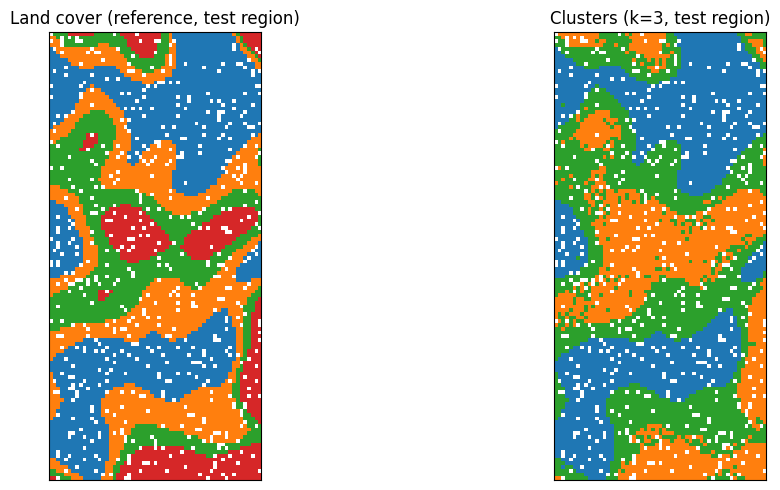

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
test_valid = test_mask & valid
land_map = np.full(SHAPE, np.nan)
cluster_map = np.full(SHAPE, np.nan)
land_map[test_valid] = scene.land_cover[test_valid]
cluster_map[test_valid] = labels_test

first_test_col = int(np.where(test_mask.any(axis=0))[0].min())
sub = (slice(None), slice(first_test_col, None))
axes[0].imshow(land_map[sub], cmap="tab10", vmin=0, vmax=9)
axes[0].set_title("Land cover (reference, test region)")
axes[1].imshow(cluster_map[sub], cmap="tab10", vmin=0, vmax=9)
axes[1].set_title(f"Clusters (k={K}, test region)")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
fig.savefig(FIG_DIR / "test_region_maps.png", dpi=120)
plt.show()

## 8. Feature space

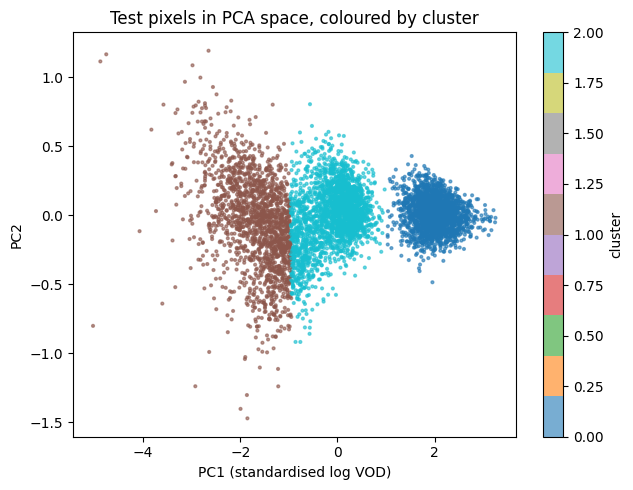

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sc = ax.scatter(Z_test[:, 0], Z_test[:, 1], c=labels_test, cmap="tab10", s=4, alpha=0.6)
ax.set_xlabel("PC1 (standardised log VOD)")
ax.set_ylabel("PC2")
ax.set_title("Test pixels in PCA space, coloured by cluster")
fig.colorbar(sc, ax=ax, label="cluster")
fig.tight_layout()
fig.savefig(FIG_DIR / "pca_clusters.png", dpi=120)
plt.show()

## 9. Interpretation, limitations and next steps

**Result 1: the headline clustering beats a single-band baseline, but only modestly.** On the held-out region, the clustering with k=3 reaches an ARI of 0.75 against land cover, compared with 0.67 for quantile binning of one band. Silhouette on test pixels is 0.63 against 0.56. The partition is also reproducible: two k-means seeds agree at ARI 0.999.

**Result 2: the silhouette criterion chooses k=3, and that merges two classes.** The sweep prefers k=3 (silhouette 0.618) over k=4 (0.581). The crosstab shows what this costs. Cluster 0 is almost pure forest (2,270 of 2,273 pixels). Cluster 2 is mostly shrubland (1,767 of 2,265), with 468 cropland pixels. Cluster 1 combines cropland (898) and grassland (798). So the cropland and grassland classes are merged, and this accounts for most of the gap between the headline ARI and the diagnostic below. Silhouette rewards well-separated groups, which is not the same as recovering the classes.

**Result 3: the features do separate all four classes when k is right.** The diagnostic sets k to the true class count. It uses land cover to choose k, so it is not a valid result, but it tests whether the features carry enough information. At k=4, the clustering reaches ARI 0.84, while the single-band baseline reaches 0.50. The gap between the two methods is wider here than at k=3. The shape across bands, not only the amplitude of one band, carries the class signal in this scene.

**Result 4: the main limitation is cluster-count selection, not the features.** A label-free rule that matches the four classes would need stronger evidence than silhouette alone. Candidates include the stability of the partition across seeds and splits, and an information criterion for a mixture model.

**Limitations**

- The scene is synthetic, and its class profiles are designed to be distinguishable. High agreement is expected in this setting and does not show performance on real observations.
- Real VOD is noisier, has irregular gaps, depends on season and retrieval algorithm, and is recorded at a coarse footprint. Land-cover maps have different resolution and classes. None of these effects is modelled.
- Moisture is modelled as one common amplitude factor. In real data the moisture response differs between bands and between vegetation types.
- There is one train/test split from one scene, with one seed. The ARI values have no confidence interval.
- The spatial buffer is 3 columns on a 120 by 120 grid. Whether it is enough depends on the spatial autocorrelation of the real data, which would need to be measured.

**Next steps**

- Repeat the evaluation over several spatial blocks, and report the spread of ARI across them.
- Run a sensitivity experiment on `MOISTURE_EFFECT`, `GAP_FRACTION` and the class separation, to find where the advantage over the baseline disappears.
- Compare k-means with a Gaussian mixture, which yields probabilities and a likelihood-based choice of k.
- For real data: pick a public VOD product and land-cover map, verify their licences and access terms, and use a small regional subset.